# 01 · Exploratory analysis: RFM, cohorts, seasonality and the funnel

Jassmin is a small Ukrainian perfume shop. This notebook looks at the **warehouse marts** (#132)
built from the shop's event-driven behavioural tracking and its OLTP tables, before any model:

1. **RFM segmentation** of customers at the latest monthly snapshot;
2. **monthly cohort retention**: of the customers whose first order was in month *m*, how many order
   again *k* months later;
3. **seasonality decomposition** of orders (8 March, December, the summer dip);
4. the **session funnel** (viewed → cart → checkout → purchase) by device and traffic source.

The data is #131's synthetic shop (seed 42, 10,000 customers, January 2024 – October 2026). It reads
only `marts.*`, never the app's tables, through a read-only connection.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.tsa.seasonal import STL

from jassmin_ml import plots
from jassmin_ml.db import read_mart
from jassmin_ml.seed import set_seeds

warnings.filterwarnings("ignore", category=FutureWarning)
set_seeds()
plots.use_style()
pd.set_option("display.precision", 2)

## The data at a glance

In [2]:
read_mart(
    """
    select
      (select count(*) from marts.dim_customers) as customers,
      (select count(*) from marts.fct_orders) as orders,
      (select count(*) from marts.fct_orders where is_revenue) as revenue_orders,
      (select round(sum(net_revenue)) from marts.fct_orders where is_revenue) as net_revenue_uah,
      (select count(*) from marts.fct_sessions) as sessions,
      (select count(*) from marts.fct_events) as events,
      (select min(order_date) from marts.fct_orders) as first_order,
      (select max(order_date) from marts.fct_orders) as last_order
    """
).T.rename(columns={0: "value"})

,value
customers,10289
orders,18067
revenue_orders,16189
net_revenue_uah,12750943.0
sessions,67362
events,997811
first_order,2024-01-04
last_order,2026-10-31


## 1. RFM segmentation

`mart_customer_features` holds point-in-time RFM per customer and month. At the latest snapshot
(1 October 2026) every customer gets a 1–5 score per dimension (quintiles; recency is reversed so
5 = most recent), and the usual rule-based segments.

In [3]:
rfm = read_mart(
    """
    select customer_key, recency_days, frequency, monetary
    from marts.mart_customer_features
    where snapshot_date = (select max(snapshot_date) from marts.mart_customer_features)
    """
)


def quintile(values: pd.Series, reverse: bool = False) -> pd.Series:
    ranks = values.rank(method="first", ascending=not reverse)
    return pd.qcut(ranks, 5, labels=[1, 2, 3, 4, 5]).astype(int)


rfm["R"] = quintile(rfm["recency_days"], reverse=True)
rfm["F"] = quintile(rfm["frequency"])
rfm["M"] = quintile(rfm["monetary"])


def segment(row: pd.Series) -> str:
    r, f = row["R"], row["F"]
    if r >= 4 and f >= 4:
        return "Champions"
    if r >= 3 and f >= 3:
        return "Loyal"
    if r >= 4 and f <= 2:
        return "New / promising"
    if r <= 2 and f >= 3:
        return "At risk"
    if r <= 2 and f <= 2:
        return "Hibernating"
    return "Need attention"


rfm["segment"] = rfm.apply(segment, axis=1)
rfm_summary = (
    rfm.groupby("segment")
    .agg(
        customers=("customer_key", "size"),
        recency_days=("recency_days", "median"),
        orders=("frequency", "mean"),
        revenue_uah=("monetary", "mean"),
        total_revenue_uah=("monetary", "sum"),
    )
    .assign(share=lambda t: t["customers"] / t["customers"].sum(),
            revenue_share=lambda t: t["total_revenue_uah"] / t["total_revenue_uah"].sum())
    .sort_values("total_revenue_uah", ascending=False)
)
rfm_summary

,customers,recency_days,orders,revenue_uah,total_revenue_uah,share,revenue_share
segment,,,,,,,
Champions,1587,70.06,3.91,3115.70,4.94e+06,0.20,0.41
At risk,1731,517.59,1.82,1450.80,2.51e+06,0.22,0.21
Loyal,1484,211.21,1.86,1463.27,2.17e+06,0.19,0.18
Hibernating,1470,541.84,1.00,774.46,1.14e+06,0.18,0.09
New / promising,1084,99.19,1.00,756.85,8.20e+05,0.14,0.07
Need attention,647,244.17,1.00,716.32,4.63e+05,0.08,0.04


**Champions** (recent and frequent, 20 % of customers) bring about 41 % of the revenue, while the
*At risk* and *Hibernating* groups (40 % of customers) haven't ordered for well over a year. That
skew is the shape the generator planted (8 % loyal, 35 % one-time buyers) and the reason a churn
model and an LTV model are worth having.

## 2. Monthly cohort retention

Revenue orders (paid, shipped or completed) by month of the customer's first revenue order. The
cell is the share of the cohort that ordered in month *k* after their first.

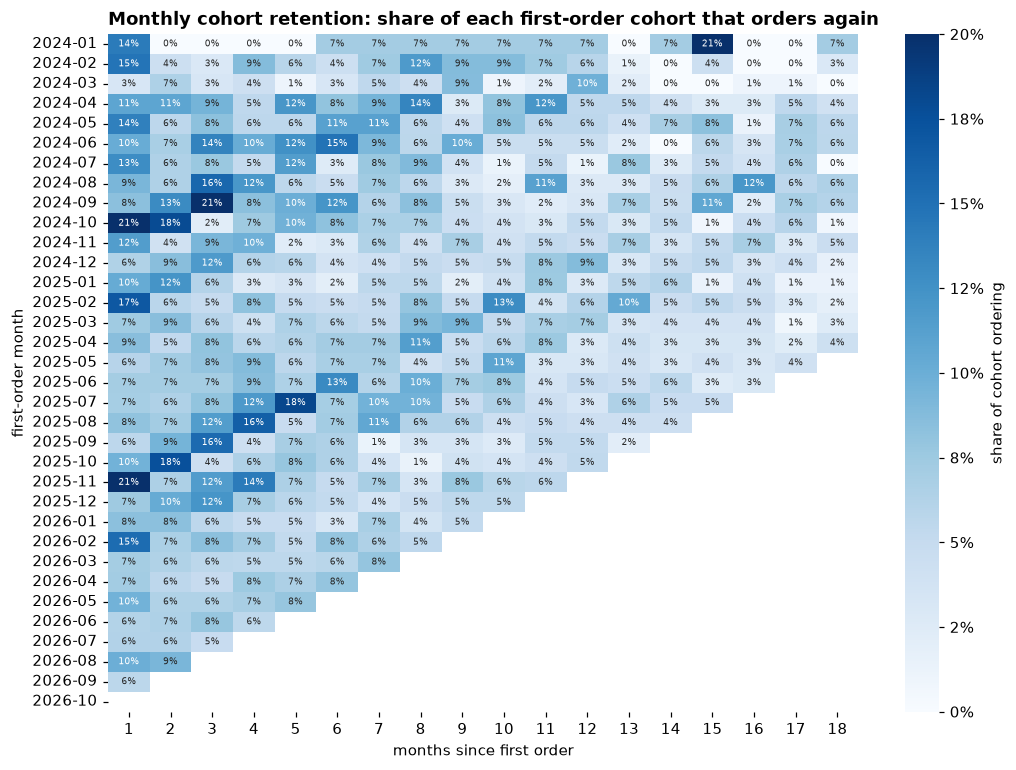

In [4]:
orders = read_mart(
    """
    select customer_key, order_date, net_revenue
    from marts.fct_orders
    where is_revenue
    """
)
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders["month"] = orders["order_date"].dt.to_period("M")
first = orders.groupby("customer_key")["month"].min().rename("cohort")
orders = orders.join(first, on="customer_key")
orders["k"] = (orders["month"] - orders["cohort"]).apply(lambda d: d.n)

active = orders.groupby(["cohort", "k"])["customer_key"].nunique().unstack(fill_value=0)
retention = active.div(active[0], axis=0)
retention = retention.loc[:, 0:18]
last_month = orders["month"].max()
# Blank the cells the data can't have seen yet.
for cohort in retention.index:
    retention.loc[cohort, retention.columns > (last_month - cohort).n] = np.nan

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    retention.drop(columns=0),
    ax=ax,
    cmap="Blues",
    vmin=0,
    vmax=0.2,
    annot=True,
    fmt=".0%",
    annot_kws={"size": 6},
    cbar_kws={"format": plt.FuncFormatter(lambda v, _: f"{v:.0%}"), "label": "share of cohort ordering"},
)
ax.grid(False)
ax.set_title("Monthly cohort retention: share of each first-order cohort that orders again")
ax.set_xlabel("months since first order")
ax.set_ylabel("first-order month")
ax.set_yticklabels([str(p) for p in retention.index], rotation=0)
plots.save_figure(fig, "01_cohort_retention")
plt.show()

In [5]:
cohort_sizes = active[0].rename("cohort_size")
month_1_to_6 = retention.loc[:, 1:6].mean(axis=1).rename("mean_retention_m1_m6")
pd.concat([cohort_sizes, month_1_to_6], axis=1).describe().T

,count,mean,std,min,25%,50%,75%,max
cohort_size,34.0,246.94,151.81,14.00,131.75,241.00,325.00,710.00
mean_retention_m1_m6,33.0,0.08,0.02,0.04,0.07,0.08,0.09,0.12


About 8 % of a cohort orders again in any one of its first six months, and that share decays only
slowly, to 3–5 % a month by the second year: a few frequent buyers (the loyal and regular
customers) keep ordering while most of the cohort never comes back. Gift-season cohorts (December,
February–March) are two to three times larger than summer ones but come back *less* often in their
first six months (about 5–8 % a month against 9–10 %), partly because the months after them are the
quiet season. A gift buyer isn't automatically a loyal customer.

## 3. Seasonality: 8 March, December and the summer dip

Weekly revenue orders decomposed with STL (period 52 weeks, robust) into trend, yearly seasonality
and residual. The trend rises because signups grow over time.

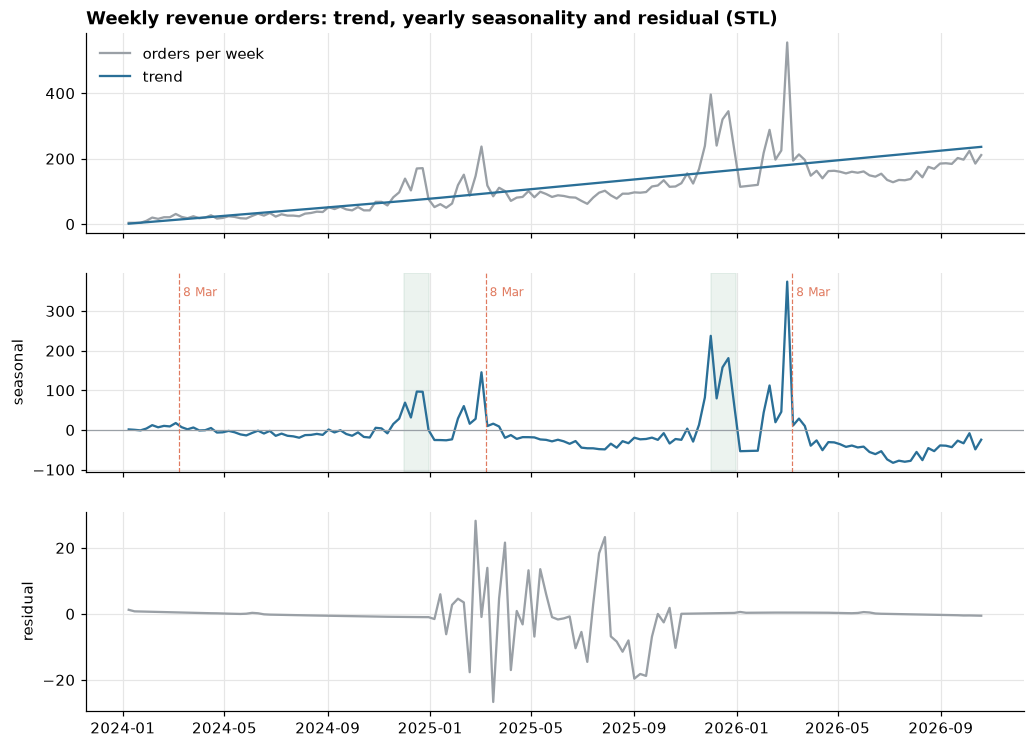

In [6]:
weekly = (
    orders.set_index("order_date")
    .resample("W-MON", label="left", closed="left")["customer_key"]
    .size()
    .rename("orders")
)
# The first and last weeks are partial.
weekly = weekly.iloc[1:-1]
stl = STL(weekly, period=52, robust=True).fit()

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(weekly.index, weekly, color=plots.MUTED, label="orders per week")
axes[0].plot(weekly.index, stl.trend, color=plots.ACCENT, label="trend")
axes[0].legend(loc="upper left")
axes[0].set_title("Weekly revenue orders: trend, yearly seasonality and residual (STL)")
axes[1].plot(weekly.index, stl.seasonal, color=plots.ACCENT)
axes[1].axhline(0, color=plots.MUTED, lw=0.8)
axes[1].set_ylabel("seasonal")
axes[2].plot(weekly.index, stl.resid, color=plots.MUTED)
axes[2].set_ylabel("residual")
for year in (2024, 2025, 2026):
    axes[1].axvline(pd.Timestamp(year, 3, 8), color=plots.PALETTE[1], lw=0.8, ls="--")
    axes[1].text(pd.Timestamp(year, 3, 8), axes[1].get_ylim()[1] * 0.85, " 8 Mar", color=plots.PALETTE[1], fontsize=8)
    if year < 2026:
        axes[1].axvspan(pd.Timestamp(year, 12, 1), pd.Timestamp(year, 12, 31), color=plots.PALETTE[3], alpha=0.15)
plt.show()

In [7]:
seasonal_by_month = (
    (stl.seasonal / stl.trend).groupby(weekly.index.month).mean().rename("seasonal_index").to_frame()
)
seasonal_by_month.index.name = "month"
seasonal_by_month.sort_values("seasonal_index", ascending=False).head(6)

,seasonal_index
month,
12,0.84
2,0.59
3,0.44
11,0.13
1,-0.08
4,-0.14


December, February and March are the strongest months relative to the trend (St Nicholas Day and
New Year, 14 February, 8 March), and the summer is the low point. That matches the generator's
multipliers (December 1.6, February 1.15 with × 1.9 on 7–14 February, March 1.25 with × 2.6 on
1–8 March, July 0.75) and is what the demand forecast (notebook 05) has to capture with calendar
features.

## 4. Funnel by device and traffic source

Per session: viewed a product → added to cart → started checkout → purchased (`fct_sessions`, bots
already removed in the warehouse).

In [8]:
sessions = read_mart(
    """
    select device_type, traffic_source, viewed_product, added_to_cart, started_checkout, purchased
    from marts.fct_sessions
    """
)
steps = ["viewed_product", "added_to_cart", "started_checkout", "purchased"]


def funnel(by: str) -> pd.DataFrame:
    table = sessions.groupby(by)[steps].mean()
    table.insert(0, "sessions", sessions.groupby(by).size())
    table["cart_to_purchase"] = table["purchased"] / table["added_to_cart"]
    return table.sort_values("sessions", ascending=False)


funnel("device_type")

,sessions,viewed_product,added_to_cart,started_checkout,purchased,cart_to_purchase
device_type,,,,,,
mobile,46380,1.0,0.37,0.27,0.27,0.71
desktop,15457,1.0,0.38,0.27,0.27,0.72
tablet,3504,1.0,0.39,0.28,0.28,0.72
unknown,2021,1.0,0.37,0.26,0.26,0.71


In [9]:
funnel("traffic_source")

,sessions,viewed_product,added_to_cart,started_checkout,purchased,cart_to_purchase
traffic_source,,,,,,
instagram,23057,1.0,0.38,0.27,0.27,0.71
google,14975,1.0,0.38,0.27,0.27,0.70
direct,10713,1.0,0.37,0.26,0.26,0.71
t.me,7978,1.0,0.37,0.26,0.26,0.71
friend,6045,1.0,0.38,0.27,0.27,0.72
facebook,4594,1.0,0.39,0.29,0.29,0.73


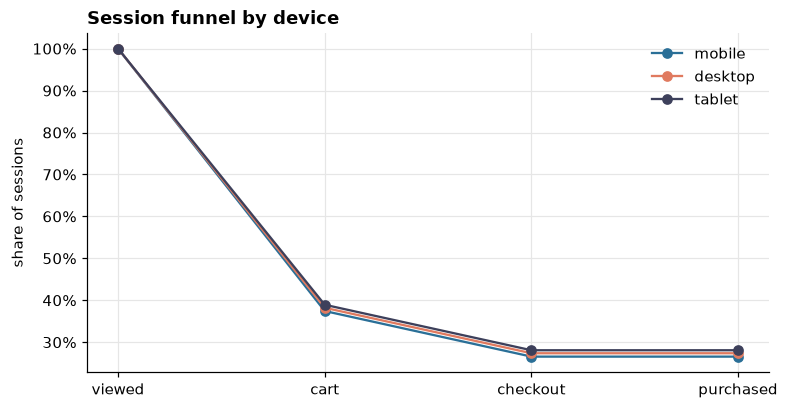

In [10]:
by_device = funnel("device_type").drop(index="unknown", errors="ignore")
fig, ax = plt.subplots(figsize=(8, 4))
for device, row in by_device.iterrows():
    ax.plot(range(len(steps)), row[steps].to_numpy(), marker="o", label=device)
ax.set_xticks(range(len(steps)), ["viewed", "cart", "checkout", "purchased"])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Session funnel by device")
ax.set_ylabel("share of sessions")
ax.legend()
plt.show()

Phones bring about 70 % of the sessions, and Instagram is the biggest source. The funnel itself is
almost identical across devices and channels: about 37–39 % of sessions add to the cart, and about
71 % of those end in a purchase. So the differences in customer value between channels (notebook
02) come from repeat behaviour, not from the first visit, and the cart, not the device, is where
the funnel leaks.

## Checks

In [11]:
top_months = seasonal_by_month["seasonal_index"].nlargest(3).index.tolist()
assert set(top_months) == {12, 2, 3}, f"December, February and March should lead: {top_months}"
assert seasonal_by_month["seasonal_index"].idxmin() in (6, 7, 8), "the summer should be the low point"
assert rfm["customer_key"].is_unique
assert abs(rfm_summary["share"].sum() - 1) < 1e-9
print("01 checks passed: seasonality peaks in", top_months)

01 checks passed: seasonality peaks in [12, 2, 3]
